# 02. Перевірка коду + класифікатор-оцінювач

1. Перевіряємо чи бачить PyTorch GPU.
2. Форми тензорів і кількість параметрів у всіх 6 варіантах моделей.
3. **Перенавчання одного батчу** — модель має вміти «запам'ятати» 64 картинки.
4. **Короткий запуск** на всіх даних — loss падає, генерації стають схожими на цифри; вимірюємо швидкість.
5. **Відтворюваність** — однаковий сід → однакові результати.
6. **Класифікатор-оцінювач** — окрема CNN, якою міряємо якість генерації (FID, впевненість, точність CVAE).

In [1]:
import sys
from pathlib import Path

# Корінь проєкту = найближча папка вгору, що містить src/ і configs/
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir() and (p / "configs").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

%matplotlib inline
%load_ext autoreload
%autoreload 2

In [2]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch

from src.utils import load_config, get_device, set_seed, save_json, RESULTS_DIR
from src.data import get_data, load_mnist_tensors, make_split
from src.models import GenerativeAE, count_params
from src.losses import compute_loss
from src.train import train_model, train_evaluator, load_evaluator, EVALUATOR_PATH
from src.metrics import evaluate_run, classifier_outputs, fid_from_features
from src.experiment import list_experiment_files, expand_experiment
from src.utils import run_name
from src.viz import setup_style, show_grid, save_fig, COLORS

setup_style()

## 1. Середовище

In [3]:
device = get_device()
print("torch:", torch.__version__, "| CUDA:", torch.version.cuda, "| device:", device)
if device.type == "cuda":
    props = torch.cuda.get_device_properties(0)
    print(f"GPU: {props.name}, {props.total_memory / 1024**3:.1f} GB")
else:
    print("⚠️ GPU не знайдено")

torch: 2.14.1+cu126 | CUDA: 12.6 | device: cuda
GPU: NVIDIA GeForce RTX 2060, 6.0 GB


## 2. Форми та кількість параметрів

In [4]:
x = torch.rand(8, 1, 28, 28, device=device)
y = torch.randint(0, 10, (8,), device=device)
rows = []
for t in ["ae", "vae", "cvae"]:
    for a in ["mlp", "conv"]:
        m = GenerativeAE(t, a, latent_dim=16).to(device)
        out = m(x, y)
        assert out["logits"].shape == x.shape
        assert out["mu"].shape == (8, 16)
        assert (out["logvar"] is None) == (t == "ae")
        rows.append({"model": t, "arch": a, "params": count_params(m),
                     "output": tuple(out["logits"].shape)})
pd.DataFrame(rows)

,model,arch,params,output
0,ae,mlp,1075488,"(8, 1, 28, 28)"
1,ae,conv,1684177,"(8, 1, 28, 28)"
2,vae,mlp,1079600,"(8, 1, 28, 28)"
3,vae,conv,1688289,"(8, 1, 28, 28)"
4,cvae,mlp,1087280,"(8, 1, 28, 28)"
5,cvae,conv,1693409,"(8, 1, 28, 28)"


## 3. Перенавчання одного батчу

Беремо 64 зображення і вчимо на них 300 кроків. Втрата відновлення має впасти дуже низько,
а відновлення — стати майже ідеальними.

ae: recon 558.2 → 48.5
vae: recon 512.1 → 71.9


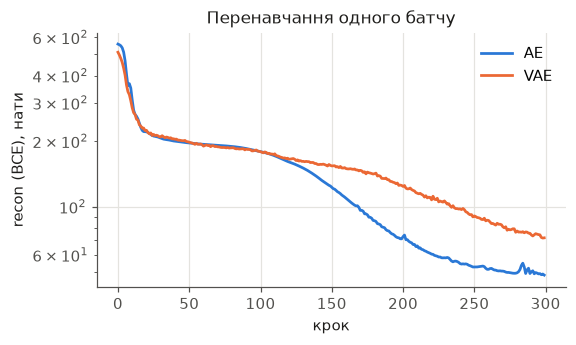

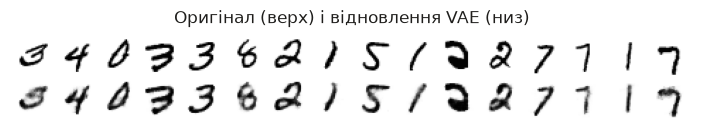

In [5]:
cfg = load_config()
data = get_data(cfg, device)
xb, yb = next(iter(data["train"]))
xb, yb = xb[:64], yb[:64]

curves = {}
for t in ["ae", "vae"]:
    set_seed(0)
    m = GenerativeAE(t, "conv", 16).to(device)
    opt = torch.optim.Adam(m.parameters(), lr=1e-3)
    hist = []
    for step in range(300):
        l = compute_loss(m(xb, yb), xb, beta=1.0, variational=m.variational)
        opt.zero_grad(); l["loss"].backward(); opt.step()
        hist.append(l["recon"].item())
    curves[t] = (m, hist)
    print(f"{t}: recon {hist[0]:.1f} → {hist[-1]:.1f}")

fig, ax = plt.subplots(figsize=(5.5, 3))
for (t, (_, h)), c in zip(curves.items(), COLORS):
    ax.plot(h, label=t.upper(), color=c)
ax.set_yscale("log"); ax.set_xlabel("крок"); ax.set_ylabel("recon (BCE), нати")
ax.set_title("Перенавчання одного батчу"); ax.legend()
plt.show()

m = curves["vae"][0]
fig, ax = plt.subplots(figsize=(8, 1.4))
show_grid(torch.cat([xb[:16], m.reconstruct(xb[:16])]), nrow=2, ax=ax,
          title="Оригінал (верх) і відновлення VAE (низ)")
plt.show()

## 4. Короткий запуск на всіх даних

1500 кроків (≈ 3.5 епохи) для VAE: втрата на train і val має падати разом, а генерації з N(0, I) — бути схожими на цифри.

20:53:42 | INFO | model={'type': 'vae', 'arch': 'conv', 'latent_dim': 16} params=1,688,289 device=cuda n_train=55000 steps=1500 (~3.5 епох)
20:53:44 | INFO | step    250 | train loss 198.46 (rec 193.30, kl 5.16) | val loss 150.54 *
20:53:46 | INFO | step    500 | train loss 133.81 (rec 118.08, kl 15.73) | val loss 124.44 *
20:53:47 | INFO | step    750 | train loss 117.02 (rec 98.29, kl 18.74) | val loss 113.33 *
20:53:49 | INFO | step   1000 | train loss 110.22 (rec 90.38, kl 19.84) | val loss 109.89 *
20:53:50 | INFO | step   1250 | train loss 107.48 (rec 87.10, kl 20.38) | val loss 106.95 *
20:53:52 | INFO | step   1500 | train loss 105.57 (rec 84.87, kl 20.70) | val loss 105.42 *
20:53:52 | INFO | Готово за 10 с, найкращий крок 1500, val loss 105.42


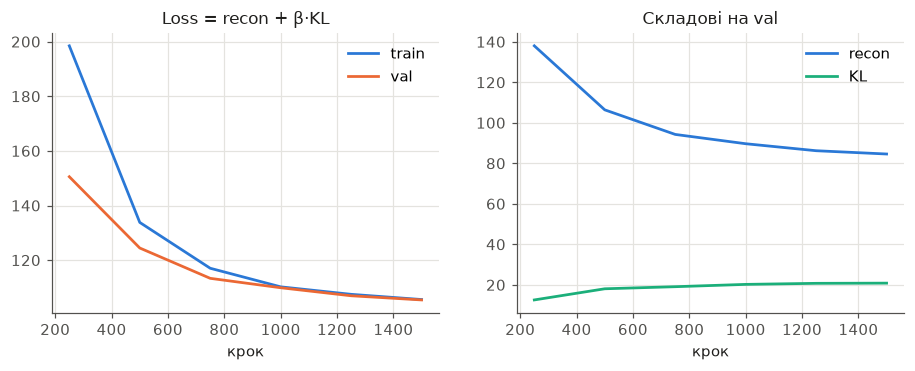

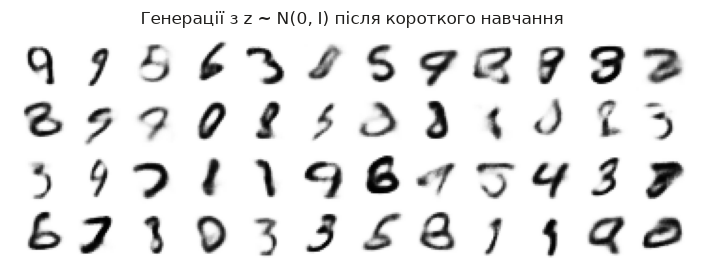

In [6]:
short_cfg = load_config(overrides={"train.steps": 1500, "train.eval_every": 250})
t0 = time.time()
model, history, info = train_model(short_cfg, run_dir=None, verbose=True)
sec_per_step = (time.time() - t0) / short_cfg["train"]["steps"]
h = pd.DataFrame(history)

fig, axes = plt.subplots(1, 2, figsize=(10, 3.3))
axes[0].plot(h["step"], h["train_loss"], label="train", color=COLORS[0])
axes[0].plot(h["step"], h["val_loss"], label="val", color=COLORS[1])
axes[0].set_title("Loss = recon + β·KL"); axes[0].set_xlabel("крок"); axes[0].legend()
axes[1].plot(h["step"], h["val_recon"], label="recon", color=COLORS[0])
axes[1].plot(h["step"], h["val_kl"], label="KL", color=COLORS[2])
axes[1].set_title("Складові на val"); axes[1].set_xlabel("крок"); axes[1].legend()
plt.show()

fig, ax = plt.subplots(figsize=(8, 2.8))
show_grid(model.sample(48), nrow=4, ax=ax, title="Генерації з z ~ N(0, I) після короткого навчання")
plt.show()

### Оцінка часу всіх експериментів

Рахуємо **унікальні** запуски (однакові конфіги в різних експериментах виконуються один раз).

In [7]:
all_runs, per_exp = set(), []
for f in list_experiment_files():
    cfgs = expand_experiment(f)
    names = [run_name(c) for c in cfgs]
    new = [n for n in names if n not in all_runs]
    all_runs.update(names)
    per_exp.append({"experiment": f.stem, "запусків": len(names), "нових унікальних": len(new)})
steps_full = load_config()["train"]["steps"]
eval_overhead_s = 10  # оцінювання одного запуску (генерація 20k зразків, FID тощо), грубо
est_h = len(all_runs) * (steps_full * sec_per_step + eval_overhead_s) / 3600
display(pd.DataFrame(per_exp))
print(f"Унікальних запусків: {len(all_runs)}; {sec_per_step * 1000:.1f} мс/крок → "
      f"орієнтовно {est_h:.1f} год на всі експерименти")

,experiment,запусків,нових унікальних
0,e1_ae_vs_vae,6,6
1,e2_latent_dim,18,15
2,e3_beta,18,15
3,e4_architecture,6,3
4,e5_data_fraction,18,15
5,e6_cvae,9,9


Унікальних запусків: 63; 6.9 мс/крок → орієнтовно 1.6 год на всі експерименти


## 5. Відтворюваність

Два запуски з однаковим сідом мають дати ідентичні криві; з різним — різні.
На GPU можлива різниця в останніх знаках через недетерміновані CUDA-операції — це нормально, якщо вона ~1e-4 і менше.

In [8]:
tiny = {"train.steps": 100, "train.eval_every": 50}
_, h_a, _ = train_model(load_config(overrides={**tiny, "seed": 0}), verbose=False)
_, h_b, _ = train_model(load_config(overrides={**tiny, "seed": 0}), verbose=False)
_, h_c, _ = train_model(load_config(overrides={**tiny, "seed": 1}), verbose=False)
d_same = max(abs(a["val_loss"] - b["val_loss"]) for a, b in zip(h_a, h_b))
d_diff = max(abs(a["val_loss"] - c["val_loss"]) for a, c in zip(h_a, h_c))
print(f"однаковий сід: max |Δ val_loss| = {d_same:.2e}")
print(f"різні сіди:    max |Δ val_loss| = {d_diff:.2e}")

однаковий сід: max |Δ val_loss| = 0.00e+00
різні сіди:    max |Δ val_loss| = 1.10e+00


## 6. Класифікатор-оцінювач

Невелика CNN, навчена на тих самих 55k train-зображеннях. Лише оцінює:
- **ознаки** передостаннього шару (128-вимірні) → FID між генераціями і тестом;
- **ймовірності** → чи впізнається згенерована цифра, наскільки впевнено, чи всі класи представлені.

Очікувана точність на тесті ≈ 99%. Навчання — 6 епох.

In [9]:
clf, clf_metrics = train_evaluator(epochs=6)
clf_metrics

epoch 1: loss 0.2766, val acc 0.9724
epoch 2: loss 0.1811, val acc 0.9864
epoch 3: loss 0.0766, val acc 0.9890
epoch 4: loss 0.1751, val acc 0.9900
epoch 5: loss 0.0474, val acc 0.9910
epoch 6: loss 0.0369, val acc 0.9908
test acc = 0.9927; збережено в C:\Users\bohda\studing\neural_networks\vae-mnist\checkpoints\evaluator.pt


{'val_acc': 0.9908, 'test_acc': 0.9927}

### Референсні значення метрик на справжніх даних

- **FID(train, test)** — «нижня межа»: скільки дає порівняння двох вибірок справжніх цифр.
- **Частка неоднозначних справжніх цифр** — з чим порівнюватимемо генерації.

In [10]:
x_all, y_all, x_te, y_te = load_mnist_tensors()
split = make_split(y_all)
rng = np.random.default_rng(0)
tr_sub = rng.choice(split["train_idx"], 10000, replace=False)
f_tr, p_tr = classifier_outputs(clf, x_all[tr_sub].to(device))
f_te, p_te = classifier_outputs(clf, x_te.to(device))
thr = load_config()["eval"]["ambiguous_threshold"]
reference = {
    "evaluator_test_acc": clf_metrics["test_acc"],
    "fid_train_vs_test": fid_from_features(f_tr, f_te),
    "real_ambiguous_share_test": float((p_te.max(1) < thr).mean()),
    "real_mean_conf_test": float(p_te.max(1).mean()),
}
save_json(reference, RESULTS_DIR / "reference_metrics.json")
reference

{'evaluator_test_acc': 0.9927,
 'fid_train_vs_test': 4.24161916306457,
 'real_ambiguous_share_test': 0.0205,
 'real_mean_conf_test': 0.9926937222480774}

### Найбільш неоднозначні справжні цифри

Навіть люди іноді пишуть так, що незрозуміло, яка це цифра. Ось тестові приклади, де класифікатор найменш упевнений.

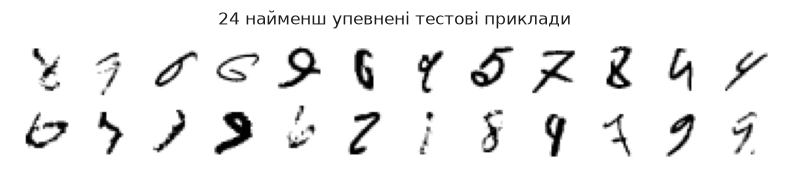

,0,1,2,3,4,5,6,7,8,9,...,14,15,16,17,18,19,20,21,22,23
справжня,8,9,0,6,9,6,9,5,7,8,...,1,9,6,2,1,8,9,7,9,9
передбачена,8,7,8,6,2,6,4,0,2,2,...,7,9,5,2,7,5,4,3,7,3
впевненість,0.28,0.35,0.43,0.44,0.45,0.46,0.46,0.49,0.49,0.49,...,0.5,0.51,0.51,0.51,0.52,0.52,0.53,0.54,0.54,0.54


In [11]:
conf = p_te.max(1)
worst = np.argsort(conf)[:24]
fig, ax = plt.subplots(figsize=(9, 1.6))
show_grid(x_te[worst], nrow=2, ax=ax, title="24 найменш упевнені тестові приклади")
plt.show()
pd.DataFrame({"справжня": y_te[worst].numpy(), "передбачена": p_te[worst].argmax(1),
              "впевненість": conf[worst].round(2)}).astype(str).T

## 7. Перевірка метрик на моделі з короткого запуску

Перевіряємо, що `evaluate_run` відпрацьовує і повертає осмислені значення (для повністю навченої моделі
FID буде значно нижчим).

In [12]:
metrics = evaluate_run(model, clf, get_data(short_cfg, device), short_cfg)
{k: (round(v, 4) if isinstance(v, float) else v) for k, v in metrics.items()
 if k not in ("kl_per_dim", "class_hist")}

{'test_recon': 83.1817,
 'test_kl': 20.8158,
 'test_nelbo': 103.9975,
 'recon_mse': 0.012,
 'active_units': 16,
 'real_ambiguous_share': 0.0205,
 'fid_prior': 473.3524,
 'class_entropy': 0.982,
 'class_share_min': 0.0598,
 'class_share_max': 0.1599,
 'mean_conf': 0.8474,
 'ambiguous_share': 0.4218,
 'fid_fitted': 386.4021,
 'ambiguous_share_fitted': 0.3698,
 'cond_acc': None}